So may: 6 | So runs: 24 | Tong so dong raw: 3612
So mau moi run (Min/Max): 150 - 152


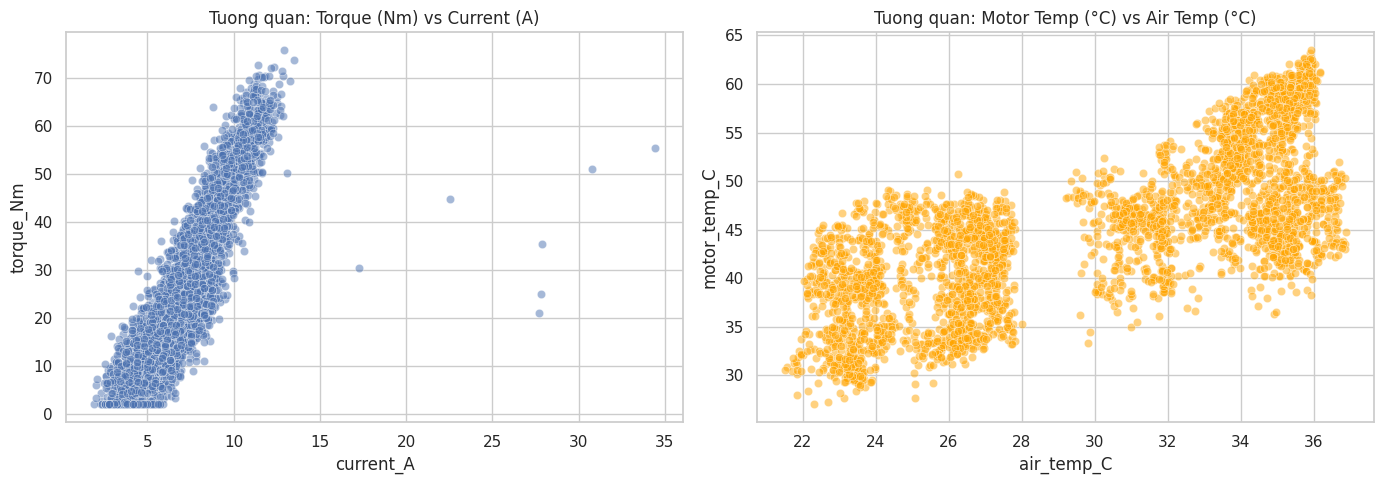


--- BANG TOM TAT GIA TRI THIEU (NaN) ---
                Missing_Count  Missing_Pct (%)
torque_Nm                   9             0.25
current_A                  12             0.33
air_temp_C                 14             0.39
process_temp_C             12             0.33
vibration_rms              10             0.28
pressure_bar                3             0.08

So ban ghi trung sample_id: 12 | trung (run_id, time_s): 12

--- THONG KE GIOL HAN MIN/MAX & BAT THUONG ---
                     min         mean       max         std
rpm             450.0000  1751.260443  3393.440  671.563024
torque_Nm         2.0000    27.828021    75.730   16.844629
current_A         1.9240     7.286383    34.422    2.389168
air_temp_C       21.5150    29.886278    36.876    4.691259
process_temp_C   29.1050    48.526150   128.727    8.334466
tool_wear_min    26.6200   122.035986   211.850   55.891842
vibration_rms     0.1357     0.599261     2.653    0.154955
pressure_bar      2.1220     3.052860   

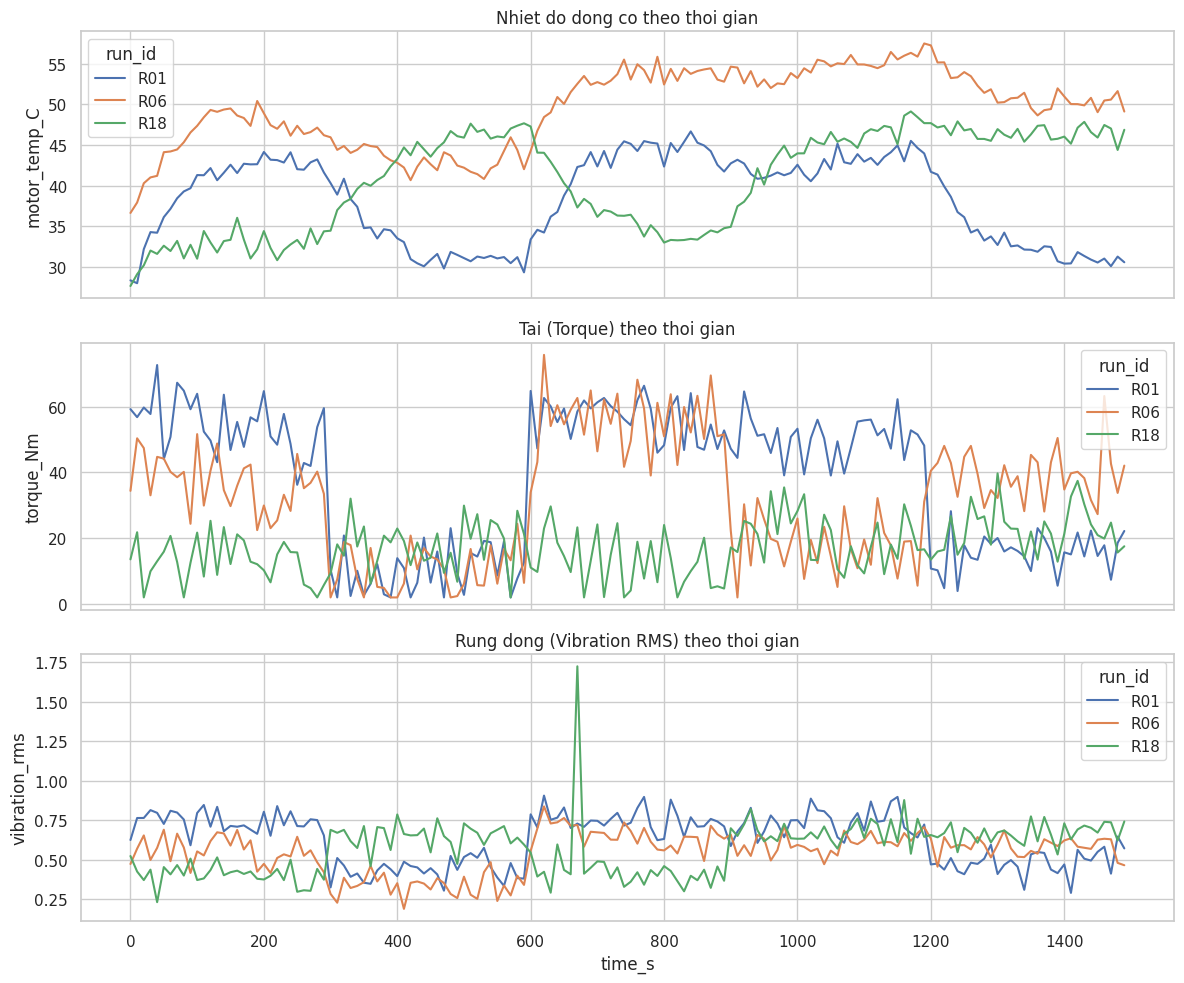

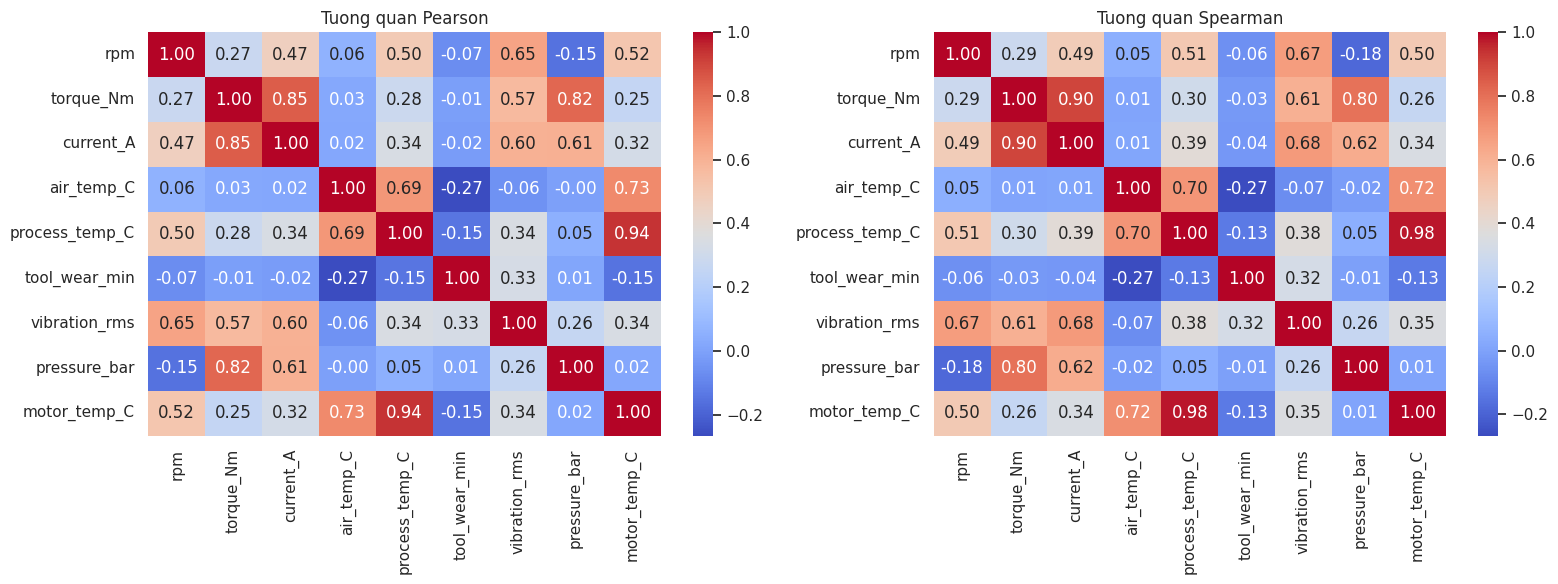

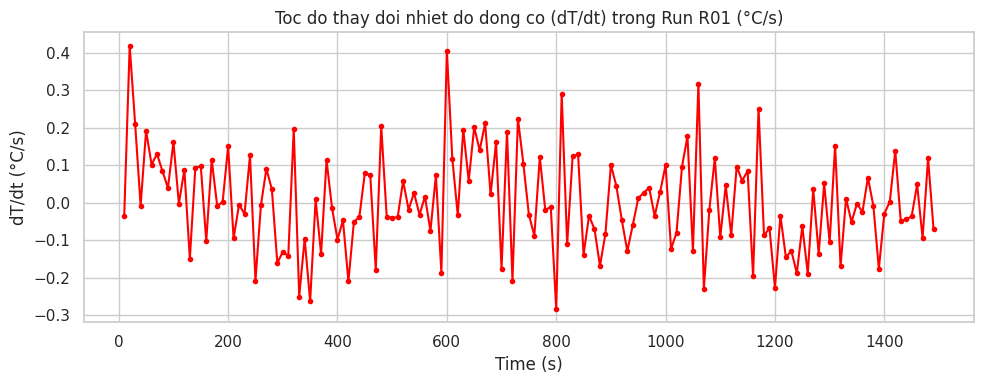


Da xuat file data_clean.csv thanh cong! Kich thuoc sau lam sach: (3600, 15)


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Cau hinh giao dien do thi
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# ==========================================
# 1. DOC DU LIEU & PHAN LOAI
# ==========================================
df_raw = pd.read_csv('motor_integrated_raw.csv')

id_cols = ['sample_id', 'machine_id', 'run_id']
time_col = ['time_s']
cat_cols = ['machine_type']
target_col = ['machine_failure']
num_cols = [c for c in df_raw.columns if c not in id_cols + time_col + cat_cols + target_col]

# ==========================================
# 2. KIEM TRA DU LIEU THO & IN KET QUA
# ==========================================
n_machines = df_raw['machine_id'].nunique()
n_runs = df_raw['run_id'].nunique()
rows_per_run = df_raw.groupby('run_id')['time_s'].count()

print(f"So may: {n_machines} | So runs: {n_runs} | Tong so dong raw: {len(df_raw)}")
print(f"So mau moi run (Min/Max): {rows_per_run.min()} - {rows_per_run.max()}")

# ==========================================
# 3. DO THI TUONG QUAN CAP BIEN TAI & NHIET DO
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=df_raw, x='current_A', y='torque_Nm', alpha=0.5, ax=axes[0])
axes[0].set_title('Tuong quan: Torque (Nm) vs Current (A)')

sns.scatterplot(data=df_raw, x='air_temp_C', y='motor_temp_C', alpha=0.5, color='orange', ax=axes[1])
axes[1].set_title('Tuong quan: Motor Temp (°C) vs Air Temp (°C)')
plt.tight_layout()
plt.show()

# ==========================================
# 4. BANG TOM TAT NaN, TRUNG LAP & THONG KE MIN/MAX
# ==========================================
nan_summary = pd.DataFrame({
    'Missing_Count': df_raw.isnull().sum(),
    'Missing_Pct (%)': (df_raw.isnull().mean() * 100).round(2)
})

dup_sample = df_raw.duplicated(subset=['sample_id']).sum()
dup_run_time = df_raw.duplicated(subset=['run_id', 'time_s']).sum()

stats_summary = df_raw[num_cols].describe().T[['min', 'mean', 'max', 'std']]

print("\n--- BANG TOM TAT GIA TRI THIEU (NaN) ---")
print(nan_summary[nan_summary['Missing_Count'] > 0])
print(f"\nSo ban ghi trung sample_id: {dup_sample} | trung (run_id, time_s): {dup_run_time}")
print("\n--- THONG KE GIOL HAN MIN/MAX & BAT THUONG ---")
print(stats_summary)

# ==========================================
# 5. LOAI BO TRUNG LAP & NOI SUY DULIEU THIEU
# ==========================================
# Sap xep va xoa trung lap theo chuoi thoi gian tung run
df_clean = df_raw.drop_duplicates(subset=['run_id', 'time_s']).sort_values(['run_id', 'time_s']).reset_index(drop=True)

# Noi suy tuyen tinh cho cac bien so do theo tung run
for col in num_cols:
    df_clean[col] = df_clean.groupby('run_id')[col].transform(lambda group: group.interpolate(method='linear').ffill().bfill())

# ==========================================
# 6. VE DIEU KIEN VAN HANH THEO THOI GIAN (2-3 RUNS)
# ==========================================
sample_runs = ['R01', 'R06', 'R18']
df_sample = df_clean[df_clean['run_id'].isin(sample_runs)]

fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
sns.lineplot(data=df_sample, x='time_s', y='motor_temp_C', hue='run_id', ax=axes[0])
axes[0].set_title('Nhiet do dong co theo thoi gian')

sns.lineplot(data=df_sample, x='time_s', y='torque_Nm', hue='run_id', ax=axes[1])
axes[1].set_title('Tai (Torque) theo thoi gian')

sns.lineplot(data=df_sample, x='time_s', y='vibration_rms', hue='run_id', ax=axes[2])
axes[2].set_title('Rung dong (Vibration RMS) theo thoi gian')
plt.tight_layout()
plt.show()

# ==========================================
# 7. MA TRAN TUONG QUAN PEARSON / SPEARMAN
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(df_clean[num_cols].corr(method='pearson'), annot=True, fmt=".2f", cmap='coolwarm', ax=axes[0])
axes[0].set_title('Tuong quan Pearson')

sns.heatmap(df_clean[num_cols].corr(method='spearman'), annot=True, fmt=".2f", cmap='coolwarm', ax=axes[1])
axes[1].set_title('Tuong quan Spearman')
plt.tight_layout()
plt.show()

# ==========================================
# 8. TINH TOC DO THAY DOI NHIET DO (dT/dt) TRONG RUN R01
# ==========================================
r01_df = df_clean[df_clean['run_id'] == 'R01'].copy()
# Toc do thay doi nhiet do (°C/s) = delta(T) / delta(t)
r01_df['dT_dt_motor'] = r01_df['motor_temp_C'].diff() / r01_df['time_s'].diff()

plt.figure(figsize=(10, 4))
plt.plot(r01_df['time_s'], r01_df['dT_dt_motor'], color='red', marker='o', linestyle='-', markersize=3)
plt.title('Toc do thay doi nhiet do dong co (dT/dt) trong Run R01 (°C/s)')
plt.xlabel('Time (s)')
plt.ylabel('dT/dt (°C/s)')
plt.tight_layout()
plt.show()

# ==========================================
# 9. XUAT FILE CLEAN DATA
# ==========================================
df_clean.to_csv('data_clean.csv', index=False)
print(f"\nDa xuat file data_clean.csv thanh cong! Kich thuoc sau lam sach: {df_clean.shape}")

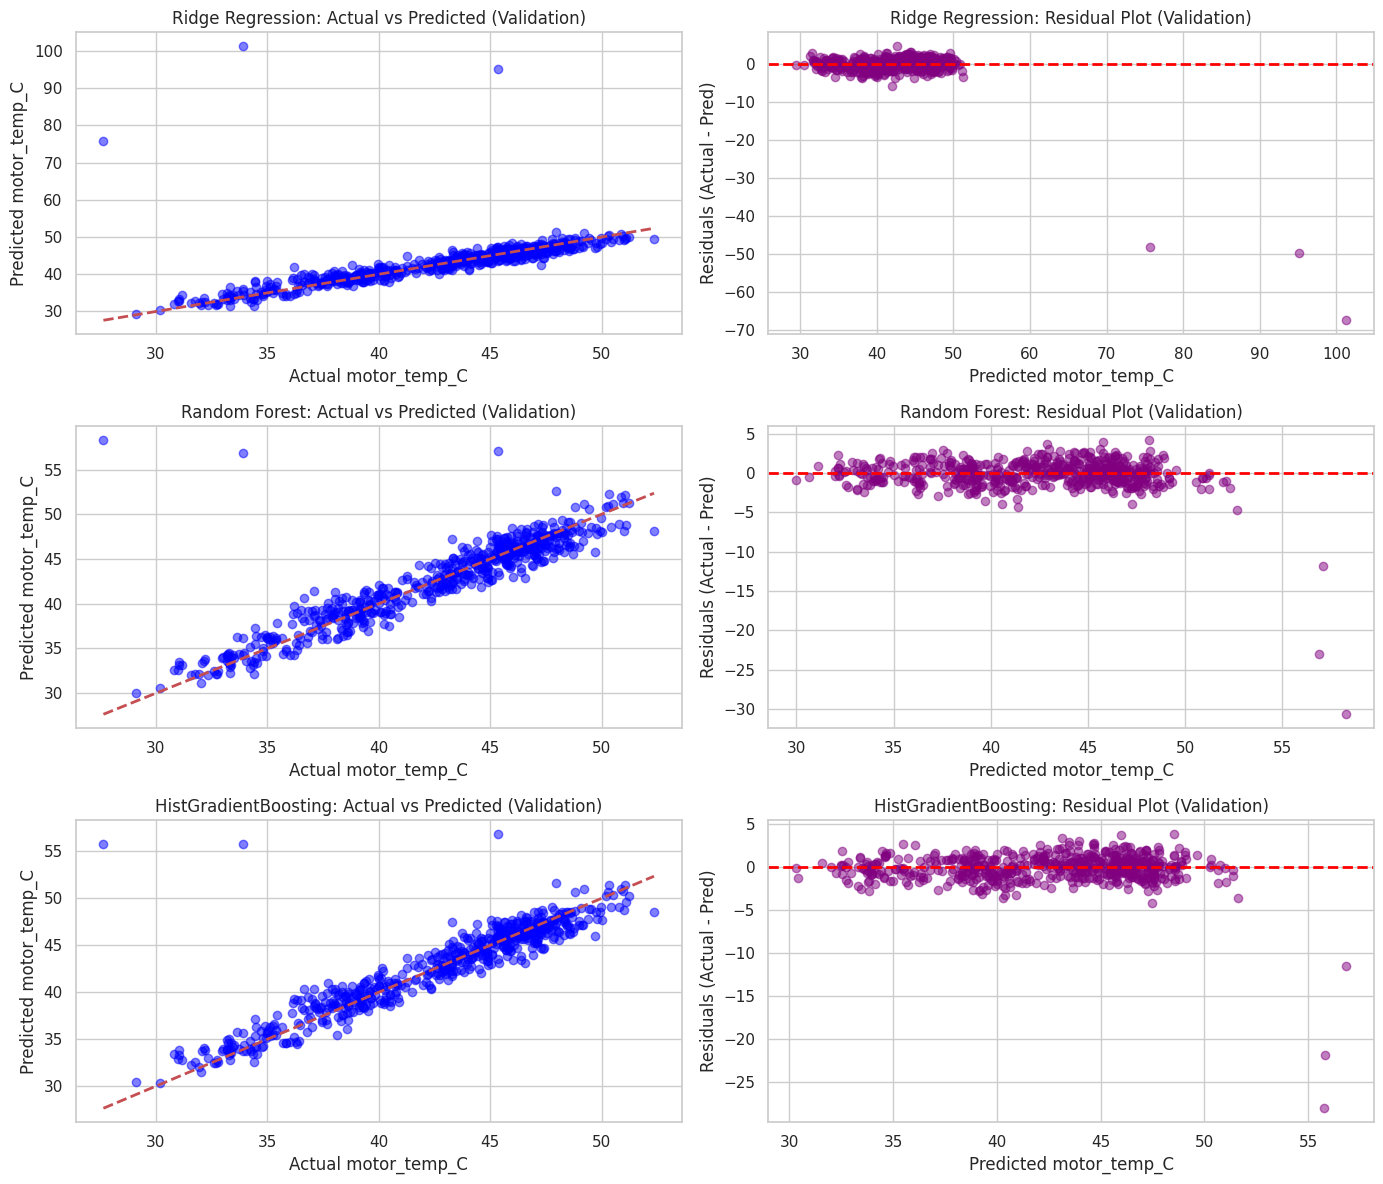

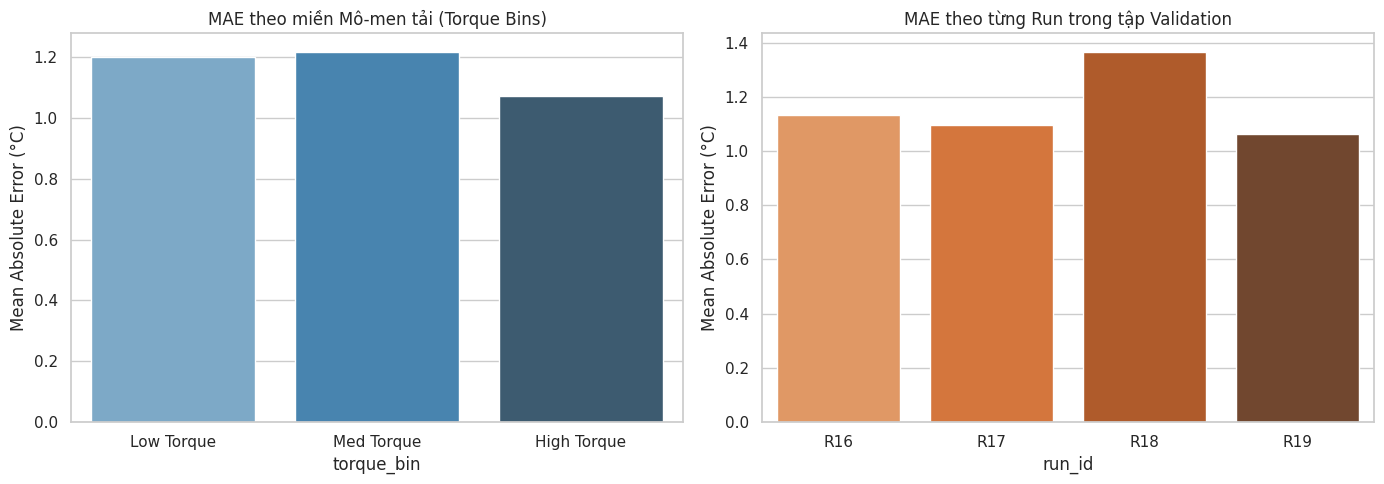

In [7]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

# Cấu hình giao diện đồ thị
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 5)

# ==========================================
# 1. ĐỌC DỮ LIỆU ĐÃ CLEAN & SETUP TARGET / FEATURES
# ==========================================
df = pd.read_csv('data_clean.csv')

target = 'motor_temp_C'
ignore_cols = ['sample_id', 'machine_id', 'run_id', 'machine_failure', target]

# One-Hot Encoding cho biến danh mục machine_type
df_encoded = pd.get_dummies(df, columns=['machine_type'], drop_first=True)
features = [c for c in df_encoded.columns if c not in ignore_cols]

# ==========================================
# 2. CHIA TRAIN - VALIDATION - TEST THEO RUN_ID
# ==========================================
# Phân chia độc lập theo run_id để tránh rò rỉ dữ liệu chuỗi thời gian (16 Train, 4 Val, 4 Test)
train_runs = ['R00', 'R01', 'R02', 'R03', 'R04', 'R05', 'R06', 'R07', 'R08', 'R09', 'R10', 'R11', 'R12', 'R13', 'R14', 'R15']
val_runs   = ['R16', 'R17', 'R18', 'R19']
test_runs  = ['R20', 'R21', 'R22', 'R23']

train_mask = df_encoded['run_id'].isin(train_runs)
val_mask   = df_encoded['run_id'].isin(val_runs)
test_mask  = df_encoded['run_id'].isin(test_runs)

X_train, y_train = df_encoded.loc[train_mask, features], df_encoded.loc[train_mask, target]
X_val, y_val     = df_encoded.loc[val_mask, features], df_encoded.loc[val_mask, target]
X_test, y_test   = df_encoded.loc[test_mask, features], df_encoded.loc[test_mask, target]

# Chuẩn hóa đặc trưng cho mô hình tuyến tính
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled   = scaler.transform(X_val)

# ==========================================
# 3. HUẤN LUYỆN 3 THUẬT TOÁN MÔ HÌNH HÓA
# ==========================================
models = {
    'Ridge Regression': (Ridge(alpha=1.0), True),
    'Random Forest': (RandomForestRegressor(n_estimators=100, random_state=42), False),
    'HistGradientBoosting': (HistGradientBoostingRegressor(random_state=42), False)
}

eval_results = []
val_preds = {}

for name, (model, use_scaler) in models.items():
    X_tr = X_train_scaled if use_scaler else X_train
    X_va = X_val_scaled if use_scaler else X_val

    model.fit(X_tr, y_train)

    tr_pred = model.predict(X_tr)
    va_pred = model.predict(X_va)
    val_preds[name] = va_pred

    eval_results.append({
        'Model': name,
        'Train MAE': mean_absolute_error(y_train, tr_pred),
        'Val MAE': mean_absolute_error(y_val, va_pred),
        'Train RMSE': np.sqrt(mean_squared_error(y_train, tr_pred)),
        'Val RMSE': np.sqrt(mean_squared_error(y_val, va_pred)),
        'Train R2': r2_score(y_train, tr_pred),
        'Val R2': r2_score(y_val, va_pred)
    })

df_eval = pd.DataFrame(eval_results)

# ==========================================
# 4. VẼ ACTUAL - PREDICTED VÀ RESIDUAL PLOTS
# ==========================================
fig, axes = plt.subplots(len(models), 2, figsize=(14, 4 * len(models)))

for idx, (name, va_pred) in enumerate(val_preds.items()):
    residuals = y_val - va_pred

    # Đồ thị Actual vs Predicted
    axes[idx, 0].scatter(y_val, va_pred, alpha=0.5, color='blue')
    axes[idx, 0].plot([y_val.min(), y_val.max()], [y_val.min(), y_val.max()], 'r--', lw=2)
    axes[idx, 0].set_title(f'{name}: Actual vs Predicted (Validation)')
    axes[idx, 0].set_xlabel('Actual motor_temp_C')
    axes[idx, 0].set_ylabel('Predicted motor_temp_C')

    # Đồ thị Residuals vs Predicted
    axes[idx, 1].scatter(va_pred, residuals, alpha=0.5, color='purple')
    axes[idx, 1].axhline(0, color='red', linestyle='--', lw=2)
    axes[idx, 1].set_title(f'{name}: Residual Plot (Validation)')
    axes[idx, 1].set_xlabel('Predicted motor_temp_C')
    axes[idx, 1].set_ylabel('Residuals (Actual - Pred)')

plt.tight_layout()
plt.show()
# ==========================================
# 5. PHÂN TÍCH MAE THEO MIỀN MÔ-MEN TẢI VÀ TỪNG RUN
# ==========================================
# Đánh giá chi tiết sai số MAE trên mô hình Random Forest
best_val_df = df.loc[val_mask].copy()
best_val_df['pred_temp'] = val_preds['Random Forest']
best_val_df['abs_error'] = (best_val_df[target] - best_val_df['pred_temp']).abs()

# Chia miền mô-men tải (Torque) thành 3 mức: Thấp, Trung bình, Cao
best_val_df['torque_bin'] = pd.qcut(best_val_df['torque_Nm'], q=3, labels=['Low Torque', 'Med Torque', 'High Torque'])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# MAE theo miền Torque (gán hue='torque_bin' để tránh FutureWarning)
sns.barplot(
    data=best_val_df,
    x='torque_bin',
    y='abs_error',
    hue='torque_bin',
    estimator=np.mean,
    errorbar=None,
    ax=axes[0],
    palette='Blues_d'
)
if axes[0].get_legend() is not None:
    axes[0].get_legend().remove()
axes[0].set_title('MAE theo miền Mô-men tải (Torque Bins)')
axes[0].set_ylabel('Mean Absolute Error (°C)')

# MAE theo từng Validation Run (gán hue='run_id' để tránh FutureWarning)
sns.barplot(
    data=best_val_df,
    x='run_id',
    y='abs_error',
    hue='run_id',
    estimator=np.mean,
    errorbar=None,
    ax=axes[1],
    palette='Oranges_d'
)
if axes[1].get_legend() is not None:
    axes[1].get_legend().remove()
axes[1].set_title('MAE theo từng Run trong tập Validation')
axes[1].set_ylabel('Mean Absolute Error (°C)')

plt.tight_layout()
plt.show()

=== BÁO CÁO KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP VALIDATION ===
              Model  Accuracy  Balanced Acc  Precision  Recall  F1-score  ROC-AUC  AP (PR-AUC)
              Dummy  0.973333      0.500000   0.000000  0.0000  0.000000 0.500000     0.026667
Logistic Regression  0.978333      0.624144   0.800000  0.2500  0.380952 0.945634     0.605869
                kNN  0.968333      0.558219   0.285714  0.1250  0.173913 0.768996     0.176408
            SVM-RBF  0.973333      0.500000   0.000000  0.0000  0.000000 0.848780     0.611203
        Gaussian NB  0.926667      0.749572   0.195652  0.5625  0.290323 0.906785     0.349518
      Decision Tree  0.963333      0.738014   0.363636  0.5000  0.421053 0.738014     0.195152
      Random Forest  0.978333      0.745719   0.615385  0.5000  0.551724 0.939908     0.523898


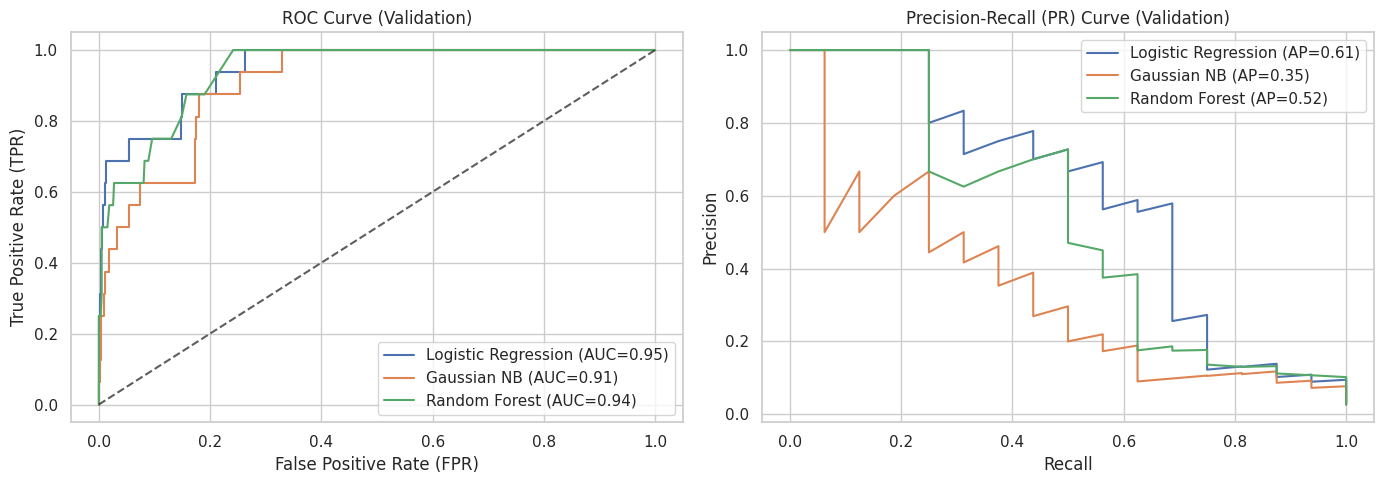

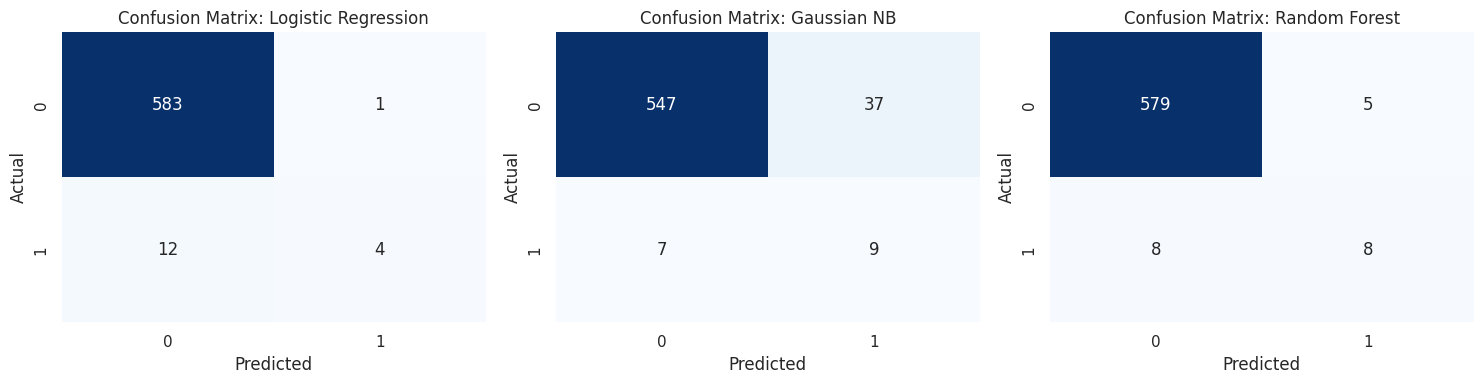


=== SO SÁNH NGƯỠNG MẶC ĐỊNH (0.5) VÀ NGƯỠNG TỐI ƯU CHI PHÍ TÊN VALIDATION ===
Ngưỡng 0.50 | Cost: 125 | FN: 8, FP: 5 | Recall: 0.5000, Precision: 0.6154
Ngưỡng 0.28 | Cost: 107 | FN: 6, FP: 17 | Recall: 0.6250, Precision: 0.3704

=== 5.1 Khảo sát ngưỡng theo tỷ lệ chi phí C_FN / C_FP ===
  C_FN =  5, C_FP = 1 -> Ngưỡng tối ưu: 0.52
  C_FN = 10, C_FP = 1 -> Ngưỡng tối ưu: 0.28
  C_FN = 15, C_FP = 1 -> Ngưỡng tối ưu: 0.28
  C_FN = 20, C_FP = 1 -> Ngưỡng tối ưu: 0.05
  C_FN = 30, C_FP = 1 -> Ngưỡng tối ưu: 0.02

=== 5.2 Khảo sát ngưỡng khi xoay vòng tập Validation Runs ===
  Val = R00-R03             -> Ngưỡng tối ưu: 0.14
  Val = R08-R11             -> Ngưỡng tối ưu: 0.10
  Val = R16-R19 (Default)   -> Ngưỡng tối ưu: 0.15
  Val = R20-R23             -> Ngưỡng tối ưu: 0.10

=== ĐÁNH GIÁ MÔ HÌNH CHỐT (RANDOM FOREST) TRÊN TẬP TEST ===
Test ROC-AUC: 0.9781 | Test AP: 0.5606

[Test Set] Ngưỡng = 0.50:
  Accuracy: 0.9733 | Precision: 0.5625 | Recall: 0.5000 | F1: 0.5294
  Confusion Matrix: TP

In [10]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, average_precision_score,
                             confusion_matrix, roc_curve, precision_recall_curve)

# Cấu hình đồ thị
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 5)

# Đọc dữ liệu đã tiền xử lý từ Yêu cầu 1
df = pd.read_csv('data_clean.csv')

# ==========================================
# 1. TÁCH DỮ LIỆU THEO RUN_ID & TẠO PIPELINE
# ==========================================
target = 'machine_failure'
ignore_cols = ['sample_id', 'machine_id', 'run_id', target]
num_cols = [c for c in df.columns if c not in ignore_cols and c != 'machine_type']
cat_cols = ['machine_type']

# Chia Train (16 runs), Validation (4 runs), Test (4 runs) để tránh rò rỉ theo chuỗi thời gian
train_runs = ['R00', 'R01', 'R02', 'R03', 'R04', 'R05', 'R06', 'R07', 'R08', 'R09', 'R10', 'R11', 'R12', 'R13', 'R14', 'R15']
val_runs   = ['R16', 'R17', 'R18', 'R19']
test_runs  = ['R20', 'R21', 'R22', 'R23']

train_df = df[df['run_id'].isin(train_runs)]
val_df   = df[df['run_id'].isin(val_runs)]
test_df  = df[df['run_id'].isin(test_runs)]

X_train, y_train = train_df[num_cols + cat_cols], train_df[target]
X_val, y_val     = val_df[num_cols + cat_cols], val_df[target]
X_test, y_test   = test_df[num_cols + cat_cols], test_df[target]

# Pipeline xử lý đặc trưng số và đặc trưng danh mục
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols)
    ]
)

# ==========================================
# 2. HUẤN LUYỆN DUMMY VÀ 6 MÔ HÌNH PHÂN LOẠI
# ==========================================
classifiers = {
    'Dummy': DummyClassifier(strategy='most_frequent'),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'kNN': KNeighborsClassifier(n_neighbors=5),
    'SVM-RBF': SVC(probability=True, random_state=42),
    'Gaussian NB': GaussianNB(),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42)
}

val_results = []
models_dict = {}

for name, clf in classifiers.items():
    pipe = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', clf)])
    pipe.fit(X_train, y_train)

    y_pred = pipe.predict(X_val)
    y_prob = pipe.predict_proba(X_val)[:, 1] if hasattr(pipe, "predict_proba") else pipe.decision_function(X_val)

    models_dict[name] = (pipe, y_pred, y_prob)

    val_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_val, y_pred),
        'Balanced Acc': balanced_accuracy_score(y_val, y_pred),
        'Precision': precision_score(y_val, y_pred, zero_division=0),
        'Recall': recall_score(y_val, y_pred, zero_division=0),
        'F1-score': f1_score(y_val, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_val, y_prob),
        'AP (PR-AUC)': average_precision_score(y_val, y_prob)
    })

df_val_results = pd.DataFrame(val_results)
print("=== BÁO CÁO KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP VALIDATION ===")
print(df_val_results.to_string(index=False))

# ==========================================
# 3. VẼ ĐỒ THỊ ROC, PR CURVE VÀ CONFUSION MATRIX
# ==========================================
selected_models = ['Logistic Regression', 'Gaussian NB', 'Random Forest']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name in selected_models:
    _, _, y_prob = models_dict[name]

    # ROC Curve
    fpr, tpr, _ = roc_curve(y_val, y_prob)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_val, y_prob):.2f})")

    # PR Curve
    prec, rec, _ = precision_recall_curve(y_val, y_prob)
    axes[1].plot(rec, prec, label=f"{name} (AP={average_precision_score(y_val, y_prob):.2f})")

axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.7)
axes[0].set_title('ROC Curve (Validation)')
axes[0].set_xlabel('False Positive Rate (FPR)')
axes[0].set_ylabel('True Positive Rate (TPR)')
axes[0].legend()

axes[1].set_title('Precision-Recall (PR) Curve (Validation)')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend()

plt.tight_layout()
plt.show()

# Confusion Matrices
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for idx, name in enumerate(selected_models):
    _, y_pred, _ = models_dict[name]
    cm = confusion_matrix(y_val, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx], cbar=False)
    axes[idx].set_title(f'Confusion Matrix: {name}')
    axes[idx].set_xlabel('Predicted')
    axes[idx].set_ylabel('Actual')

plt.tight_layout()
plt.show()

# ==========================================
# 4. TỐI ƯU HÓA NGƯỠNG THEO CHI PHÍ (C_FN = 15, C_FP = 1)
# ==========================================
def compute_cost(y_true, y_prob, threshold, c_fn=15, c_fp=1):
    y_pred = (y_prob >= threshold).astype(int)
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    total_cost = c_fn * fn + c_fp * fp
    return total_cost, fn, fp, tp, tn

thresholds = np.linspace(0.01, 0.99, 99)
rf_pipe, _, y_val_prob_rf = models_dict['Random Forest']

costs = [compute_cost(y_val, y_val_prob_rf, th, c_fn=15, c_fp=1)[0] for th in thresholds]
opt_th = thresholds[np.argmin(costs)]

cost_def, fn_def, fp_def, tp_def, tn_def = compute_cost(y_val, y_val_prob_rf, 0.50)
cost_opt, fn_opt, fp_opt, tp_opt, tn_opt = compute_cost(y_val, y_val_prob_rf, opt_th)

print("\n=== SO SÁNH NGƯỠNG MẶC ĐỊNH (0.5) VÀ NGƯỠNG TỐI ƯU CHI PHÍ TÊN VALIDATION ===")
print(f"Ngưỡng 0.50 | Cost: {cost_def} | FN: {fn_def}, FP: {fp_def} | Recall: {tp_def/(tp_def+fn_def):.4f}, Precision: {tp_def/(tp_def+fp_def):.4f}")
print(f"Ngưỡng {opt_th:.2f} | Cost: {cost_opt} | FN: {fn_opt}, FP: {fp_opt} | Recall: {tp_opt/(tp_opt+fn_opt):.4f}, Precision: {tp_opt/(tp_opt+fp_opt):.4f}")

# ==========================================
# 5. KHẢO SÁT ĐỘ ỔN ĐỊNH CỦA NGƯỠNG (STABILITY ANALYSIS)
# ==========================================
print("\n=== 5.1 Khảo sát ngưỡng theo tỷ lệ chi phí C_FN / C_FP ===")
for c_fn in [5, 10, 15, 20, 30]:
    c_list = [compute_cost(y_val, y_val_prob_rf, th, c_fn=c_fn, c_fp=1)[0] for th in thresholds]
    best_t = thresholds[np.argmin(c_list)]
    print(f"  C_FN = {c_fn:2d}, C_FP = 1 -> Ngưỡng tối ưu: {best_t:.2f}")

print("\n=== 5.2 Khảo sát ngưỡng khi xoay vòng tập Validation Runs ===")
val_splits = [
    (['R00','R01','R02','R03'], "Val = R00-R03"),
    (['R08','R09','R10','R11'], "Val = R08-R11"),
    (['R16','R17','R18','R19'], "Val = R16-R19 (Default)"),
    (['R20','R21','R22','R23'], "Val = R20-R23")
]

for val_r, label in val_splits:
    tr_r = [r for r in df['run_id'].unique() if r not in val_r]
    X_tr_s, y_tr_s = df[df['run_id'].isin(tr_r)][num_cols + cat_cols], df[df['run_id'].isin(tr_r)][target]
    X_va_s, y_va_s = df[df['run_id'].isin(val_r)][num_cols + cat_cols], df[df['run_id'].isin(val_r)][target]

    p = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', RandomForestClassifier(n_estimators=100, random_state=42))])
    p.fit(X_tr_s, y_tr_s)
    y_p = p.predict_proba(X_va_s)[:, 1]

    c_l = [compute_cost(y_va_s, y_p, th, c_fn=15, c_fp=1)[0] for th in thresholds]
    b_t = thresholds[np.argmin(c_l)]
    print(f"  {label:25s} -> Ngưỡng tối ưu: {b_t:.2f}")

# ==========================================
# 6. ĐÁNH GIÁ MÔ HÌNH CHỐT TRÊN TẬP TEST (R20 - R23)
# ==========================================
y_test_prob_rf = rf_pipe.predict_proba(X_test)[:, 1]

print("\n=== ĐÁNH GIÁ MÔ HÌNH CHỐT (RANDOM FOREST) TRÊN TẬP TEST ===")
print(f"Test ROC-AUC: {roc_auc_score(y_test, y_test_prob_rf):.4f} | Test AP: {average_precision_score(y_test, y_test_prob_rf):.4f}")

for th in [0.50, 0.20]:
    y_pred_t = (y_test_prob_rf >= th).astype(int)
    cost_t, fn_t, fp_t, tp_t, tn_t = compute_cost(y_test, y_test_prob_rf, th, c_fn=15, c_fp=1)
    acc_t = accuracy_score(y_test, y_pred_t)
    rec_t = recall_score(y_test, y_pred_t, zero_division=0)
    prec_t = precision_score(y_test, y_pred_t, zero_division=0)
    f1_t = f1_score(y_test, y_pred_t, zero_division=0)

    print(f"\n[Test Set] Ngưỡng = {th:.2f}:")
    print(f"  Accuracy: {acc_t:.4f} | Precision: {prec_t:.4f} | Recall: {rec_t:.4f} | F1: {f1_t:.4f}")
    print(f"  Confusion Matrix: TP={tp_t}, FP={fp_t}, FN={fn_t}, TN={tn_t}")
    print(f"  Tổng chi phí thiệt hại (Total Cost): {cost_t}")

# ==========================================
# 7. PHÂN TÍCH LỖI BỎ SÓT (FN) THEO RUN VÀ MIỀN TẢI (TORQUE)
# ==========================================
test_analysis = test_df.copy()
test_analysis['y_prob'] = y_test_prob_rf
test_analysis['y_pred_05'] = (y_test_prob_rf >= 0.50).astype(int)
test_analysis['y_pred_02'] = (y_test_prob_rf >= 0.20).astype(int)
test_analysis['torque_bin'] = pd.qcut(test_analysis['torque_Nm'], q=3, labels=['Low Torque', 'Med Torque', 'High Torque'])

fn_summary = test_analysis.groupby('torque_bin', observed=False).agg(
    total_samples=('machine_failure', 'count'),
    actual_failures=('machine_failure', 'sum'),
    fn_at_05=('y_pred_05', lambda x: ((test_analysis.loc[x.index, target] == 1) & (x == 0)).sum()),
    fn_at_02=('y_pred_02', lambda x: ((test_analysis.loc[x.index, target] == 1) & (x == 0)).sum())
)

print("\n=== BẢNG THỐNG KÊ LỖI BỎ SÓT (FN) THEO MIỀN MÔ-MEN TẢI TRÊN TẬP TEST ===")
print(fn_summary)

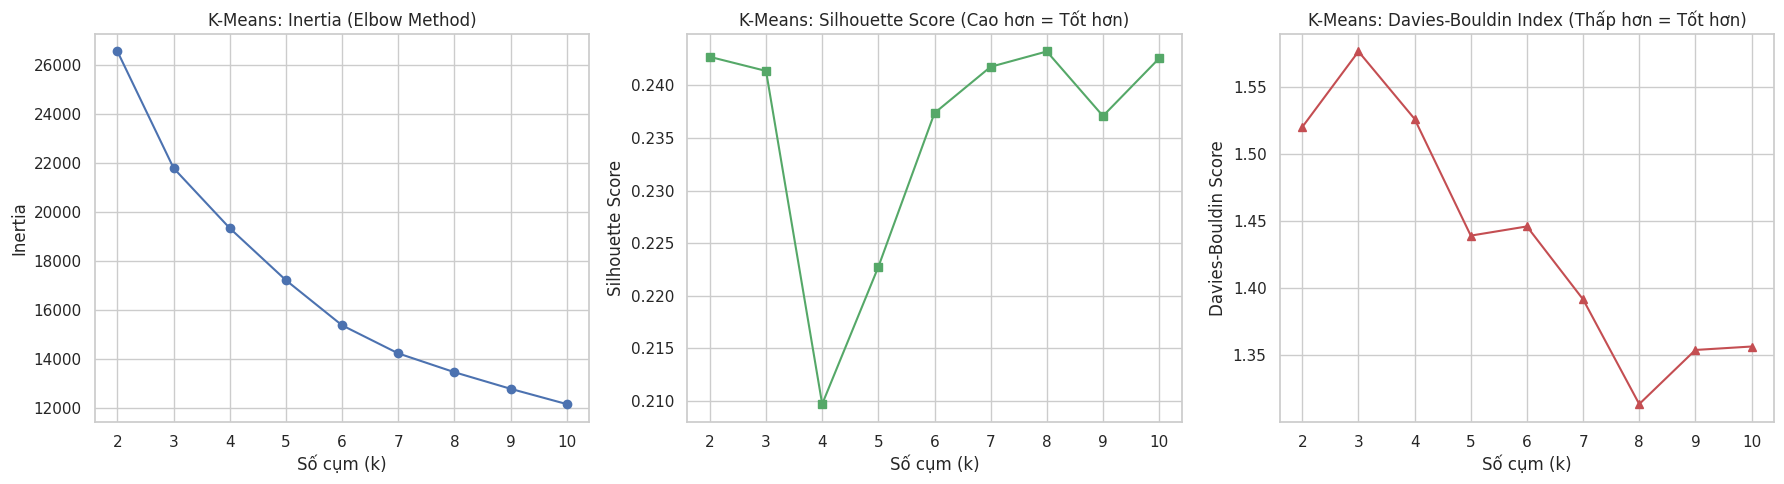

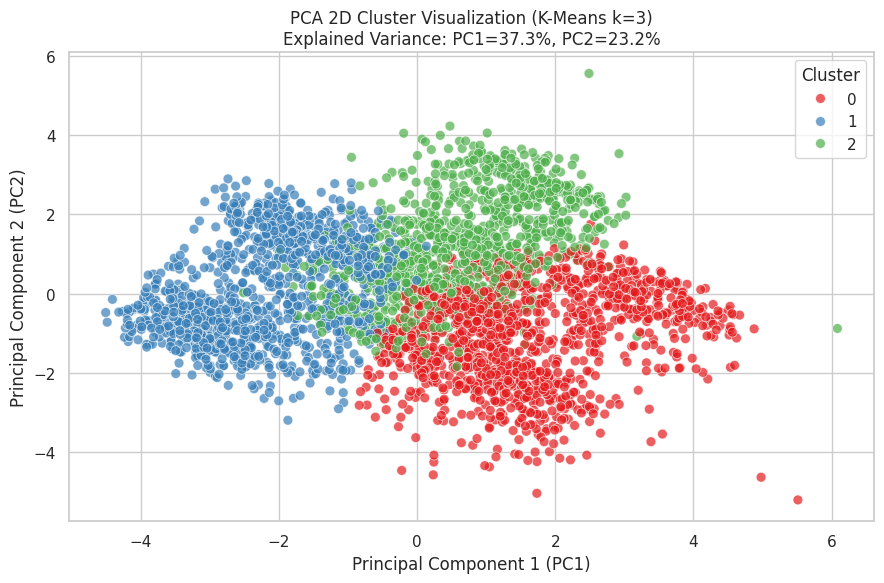

=== BẢNG THỐNG KÊ TRUNG BÌNH & ĐỘ LỆCH CHUẨN DỮ LIỆU GỐC THEO CỤM ===
               Cluster 0 (Mean ± Std) Cluster 1 (Mean ± Std)  \
time_s                 608.17 ± 426.8        763.09 ± 411.92   
rpm                   1859.1 ± 261.07       1004.33 ± 330.77   
torque_Nm               46.86 ± 10.23            14.1 ± 8.35   
current_A                 9.57 ± 1.93            5.06 ± 1.26   
air_temp_C               29.96 ± 4.43            28.98 ± 4.9   
process_temp_C           50.52 ± 6.67           41.93 ± 5.75   
tool_wear_min           124.08 ± 54.6         126.35 ± 58.08   
vibration_rms             0.69 ± 0.11             0.45 ± 0.1   
pressure_bar               3.39 ± 0.2            2.95 ± 0.19   
motor_temp_C             46.64 ± 6.62           38.86 ± 5.75   

               Cluster 2 (Mean ± Std)  
time_s                878.18 ± 417.21  
rpm                  2433.62 ± 408.06  
torque_Nm                21.44 ± 8.19  
current_A                 7.14 ± 1.08  
air_temp_C               

In [11]:

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.decomposition import PCA

# Cấu hình đồ thị
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 5)

# Đọc dữ liệu đã tiền xử lý
df = pd.read_csv('data_clean.csv')

# ==========================================
# 1. CHỌN ĐẶC TRƯNG SỐ & CHUẨN HÓA DỮ LIỆU
# ==========================================
ignore_cols = ['sample_id', 'machine_id', 'run_id', 'machine_failure', 'machine_type']
feature_cols = [c for c in df.columns if c not in ignore_cols]

X = df[feature_cols]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# ==========================================
# 2. TÌM SỐ CỤM K CHO K-MEANS (INERTIA, SILHOUETTE, DAVIES-BOULDIN)
# ==========================================
ks = range(2, 11)
inertias, silhouettes, db_scores = [], [], []

for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))
    db_scores.append(davies_bouldin_score(X_scaled, labels))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Đồ thị Elbow (Inertia)
axes[0].plot(ks, inertias, marker='o', color='b')
axes[0].set_title('K-Means: Inertia (Elbow Method)')
axes[0].set_xlabel('Số cụm (k)')
axes[0].set_ylabel('Inertia')

# Đồ thị Silhouette Score
axes[1].plot(ks, silhouettes, marker='s', color='g')
axes[1].set_title('K-Means: Silhouette Score (Cao hơn = Tốt hơn)')
axes[1].set_xlabel('Số cụm (k)')
axes[1].set_ylabel('Silhouette Score')

# Đồ thị Davies-Bouldin Index
axes[2].plot(ks, db_scores, marker='^', color='r')
axes[2].set_title('K-Means: Davies-Bouldin Index (Thấp hơn = Tốt hơn)')
axes[2].set_xlabel('Số cụm (k)')
axes[2].set_ylabel('Davies-Bouldin Score')

plt.tight_layout()
plt.show()

# ==========================================
# 3. MÔ HÌNH K-MEANS (K=3) & VẼ PCA 2D
# ==========================================
best_k = 3
km_best = KMeans(n_clusters=best_k, random_state=42, n_init=10)
df['km_cluster'] = km_best.fit_predict(X_scaled)

pca = PCA(n_components=2)
pca_coords = pca.fit_transform(X_scaled)
df['pca1'] = pca_coords[:, 0]
df['pca2'] = pca_coords[:, 1]

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df, x='pca1', y='pca2', hue='km_cluster',
    palette='Set1', alpha=0.7, s=50
)
plt.title(f'PCA 2D Cluster Visualization (K-Means k={best_k})\n'
          f'Explained Variance: PC1={pca.explained_variance_ratio_[0]*100:.1f}%, PC2={pca.explained_variance_ratio_[1]*100:.1f}%')
plt.xlabel('Principal Component 1 (PC1)')
plt.ylabel('Principal Component 2 (PC2)')
plt.legend(title='Cluster')
plt.tight_layout()
plt.show()

# ==========================================
# 4. BẢNG GIÁ TRỊ TRUNG BÌNH & ĐỘ LỆCH CHUẨN TRONG ĐƠN VỊ GỐC
# ==========================================
mean_table = df.groupby('km_cluster')[feature_cols].mean().round(2).T
std_table = df.groupby('km_cluster')[feature_cols].std().round(2).T

summary_df = pd.DataFrame()
for c in range(best_k):
    summary_df[f'Cluster {c} (Mean ± Std)'] = (
        mean_table[c].astype(str) + " ± " + std_table[c].astype(str)
    )

print("=== BẢNG THỐNG KÊ TRUNG BÌNH & ĐỘ LỆCH CHUẨN DỮ LIỆU GỐC THEO CỤM ===")
print(summary_df)

# ==========================================
# 5. THỬ NGHỆM DBSCAN VÀ AGGLOMERATIVE CLUSTERING
# ==========================================
print("\n=== THỬ NGHỆM DBSCAN (THAY ĐỔI eps VÀ min_samples) ===")
for eps in [0.8, 1.0, 1.2]:
    for min_s in [5, 10, 15]:
        db = DBSCAN(eps=eps, min_samples=min_s)
        lbls = db.fit_predict(X_scaled)
        n_c = len(set(lbls)) - (1 if -1 in lbls else 0)
        n_n = list(lbls).count(-1)
        sil = silhouette_score(X_scaled, lbls) if n_c > 1 else -1
        print(f"DBSCAN (eps={eps:3.1f}, min_samples={min_s:2d}) -> Số cụm: {n_c:2d} | Điểm nhiễu (Noise): {n_n:4d} ({n_n/len(X):.1%}) | Silhouette: {sil:.4f}")

print("\n=== THỬ NGHỆM AGGLOMERATIVE CLUSTERING ===")
for k_agg in [2, 3, 4]:
    agg = AgglomerativeClustering(n_clusters=k_agg)
    lbls = agg.fit_predict(X_scaled)
    sil = silhouette_score(X_scaled, lbls)
    db_s = davies_bouldin_score(X_scaled, lbls)
    print(f"Agglomerative (k={k_agg}) -> Silhouette: {sil:.4f} | Davies-Bouldin: {db_s:.4f}")